# 08 - Final test: walk-forward on the 2017-2022 classes

The moment of truth. **Everything is frozen** before this notebook runs:

- model: the ensemble (Ridge + splines averaged with gradient boosting), settings from 02
- tiers, adaptive-kernel tier probabilities (bandwidth 0.5, at least 50 neighbours)
- style comparables and the minutes-profile warning

**Walk-forward:** each test class gets its own model, trained only on players whose
year 4 had ended before that class's rookie season. The model for 2017 only knows
classes up to ~2013; the one for 2022 knows up to ~2018. No information from the
future reaches any prediction.

Reference sets for probabilities, comparables and the warning come from the
development set (classes 2000-2013, out-of-fold), so they are also "past only".

**After this notebook nothing in the model changes.** Test results are usually a
bit worse than cross-validation; that's expected and is the reason the test exists.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
import projection as pj
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2, SEQ_BLUE

apply_style()
df = md.add_pick_terms(m.load_table())
dev = m.dev_set(df)

# Walk-forward: one model per test class, trained on the past only
wf_model = m.walk_forward(md.ensemble, md.ALL, df).rename(columns={"pred": "model_pred"})
wf_base = m.walk_forward(md.baseline, ["pick"], df)
test = wf_model.merge(wf_base[["player_id", "pred"]].rename(columns={"pred": "base_pred"}),
                      on="player_id")
print(f"Test players: {len(test)} (classes {test['draft_year'].min()}-{test['draft_year'].max()})")
test.groupby("draft_year").agg(players=("player_id", "size"), trained_on=("n_train", "first"))

Test players: 331 (classes 2017-2022)


,players,trained_on
draft_year,,
2017,56,683
2018,57,735
2019,58,783
2020,58,837
2021,55,897
2022,47,955


## 1. The headline: does the model beat the pick on unseen classes?

For comparison, cross-validation on the development set gave RMSE 2.10 (pick
only) vs 1.89 (model), a 10% gain, and Spearman 0.27 vs 0.44.

In [2]:
y = test[m.TARGET]
headline = pd.DataFrame({
    "Baseline (pick only)": m.metrics(y, test["base_pred"]),
    "Model (pick + 25 games)": m.metrics(y, test["model_pred"]),
}).T
headline["RMSE gain %"] = [np.nan, 100 * (1 - headline.loc["Model (pick + 25 games)", "rmse"]
                                          / headline.loc["Baseline (pick only)", "rmse"])]

# Paired bootstrap: resample the test players, recompute both RMSEs each time
rng = np.random.default_rng(0)
idx = rng.integers(0, len(test), size=(5000, len(test)))
err_b = (test["base_pred"].to_numpy() - y.to_numpy()) ** 2
err_m = (test["model_pred"].to_numpy() - y.to_numpy()) ** 2
gain = np.sqrt(err_b[idx].mean(axis=1)) - np.sqrt(err_m[idx].mean(axis=1))
print(f"RMSE gain over the baseline: {gain.mean():+.3f} "
      f"(90% bootstrap range {np.percentile(gain, 5):+.3f} to {np.percentile(gain, 95):+.3f}); "
      f"model better in {100 * (gain > 0).mean():.1f}% of resamples")
headline.round(3)

RMSE gain over the baseline: +0.133 (90% bootstrap range -0.009 to +0.274); model better in 93.7% of resamples


,rmse,mae,spearman,RMSE gain %
Baseline (pick only),1.654,1.163,0.258,NaN
Model (pick + 25 games),1.519,1.126,0.331,8.2


**What to look for:** whether the gain survives on players the model never saw,
and whether its bootstrap range stays above 0. The bootstrap answers "if we had
drawn a slightly different set of test players, would the model still win?".

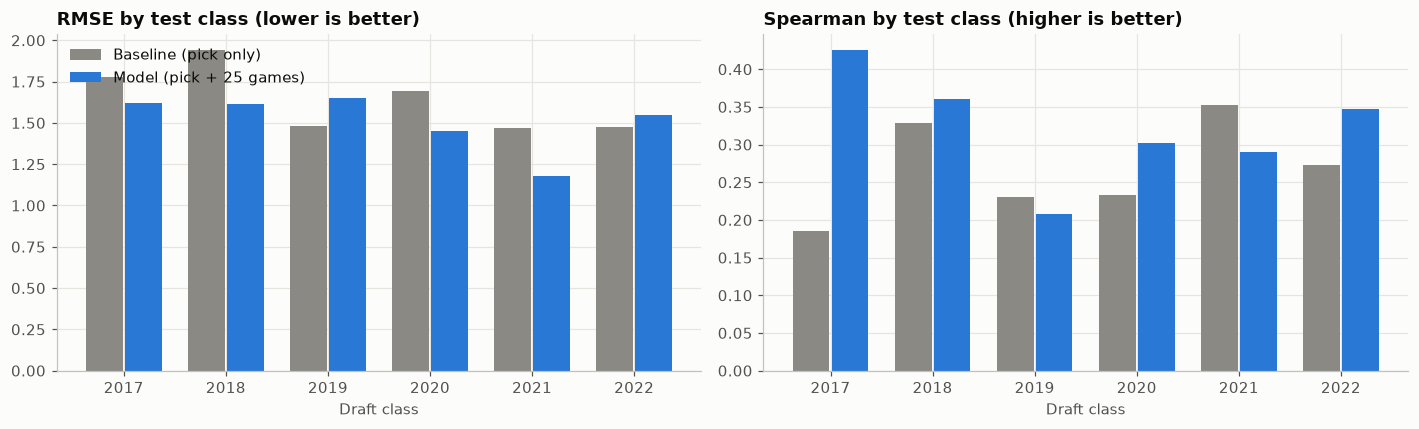

,players,baseline RMSE,model RMSE,baseline Spearman,model Spearman
class,,,,,
2017,56,1.778,1.619,0.185,0.425
2018,57,1.940,1.612,0.328,0.361
2019,58,1.479,1.650,0.230,0.207
2020,58,1.691,1.450,0.233,0.302
2021,55,1.472,1.175,0.353,0.290
2022,47,1.476,1.548,0.273,0.347


In [3]:
per_class = []
for c, g in test.groupby("draft_year"):
    b, mo = m.metrics(g[m.TARGET], g["base_pred"]), m.metrics(g[m.TARGET], g["model_pred"])
    per_class.append({"class": c, "players": len(g), "baseline RMSE": b["rmse"], "model RMSE": mo["rmse"],
                      "baseline Spearman": b["spearman"], "model Spearman": mo["spearman"]})
per_class = pd.DataFrame(per_class).set_index("class")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(per_class))
for ax, metric, better in [(axes[0], "RMSE", "lower"), (axes[1], "Spearman", "higher")]:
    ax.bar(x - 0.19, per_class[f"baseline {metric}"], width=0.36, color=NEUTRAL, label="Baseline (pick only)")
    ax.bar(x + 0.19, per_class[f"model {metric}"], width=0.36, color=BLUE, label="Model (pick + 25 games)")
    ax.set_xticks(x, per_class.index)
    ax.set(title=f"{metric} by test class ({better} is better)", xlabel="Draft class")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()
per_class.round(3)

**What to look for:** a model that only wins on average because of one lucky class
would show bars flipping from class to class. Consistent wins across the six
classes are the strongest evidence.

In [4]:
seg = pd.concat({
    "Baseline": m.by_segment(test, test["base_pred"])[["rmse", "spearman"]],
    "Model": m.by_segment(test, test["model_pred"])[["rmse", "spearman", "n"]],
}, axis=1)
seg.round(3)

Baseline           Model              
                rmse spearman   rmse spearman    n
Picks 1-10     2.565    0.338  2.440    0.397   59
Picks 11-30    1.839    0.051  1.522    0.346  120
2nd round      0.858    0.075  0.939    0.200  152

**What to look for:** whether the gain is still concentrated at picks 1-10 and in
ranking players within picks 11-30, as in cross-validation.

## 2. Calibration on unseen classes

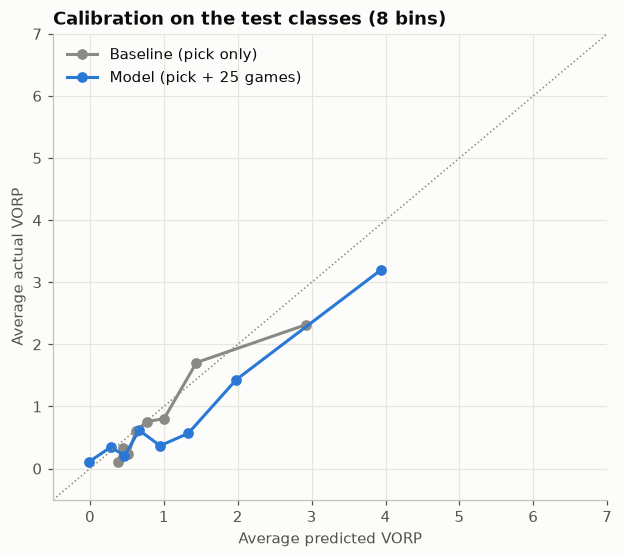

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, col, color in [("Baseline (pick only)", "base_pred", NEUTRAL), ("Model (pick + 25 games)", "model_pred", BLUE)]:
    q = pd.qcut(test[col].rank(method="first"), 8, labels=False)
    g = test.groupby(q).agg(pred=(col, "mean"), actual=(m.TARGET, "mean"))
    ax.plot(g["pred"], g["actual"], color=color, marker="o", markersize=6, label=name)
lim = [-0.5, 7]
ax.plot(lim, lim, color=NEUTRAL, linestyle=":", linewidth=1)
ax.set(title="Calibration on the test classes (8 bins)", xlabel="Average predicted VORP",
       ylabel="Average actual VORP", xlim=lim, ylim=lim)
ax.legend(loc="upper left")
plt.show()

**What to look for:** dots above the diagonal = the model was too cautious for
that group, below = too optimistic. Newer eras may sit systematically on one side
if the league changed in ways the training classes didn't show.

## 3. Tier probabilities and floor/ceiling on unseen classes

In [6]:
# Reference: development-set out-of-fold predictions (past only)
_, dev_oof = m.repeated_cv(md.ensemble, md.ALL, dev)
_, dev_base_oof = m.repeated_cv(md.baseline, ["pick"], dev)
truth_ref = dev[m.TARGET]
tidx = test.set_index("player_id")

probs = pj.tier_probabilities(tidx["model_pred"], dev_oof, truth_ref, bandwidth=0.5, min_neighbors=50)
probs_pick = pj.tier_probabilities(tidx["base_pred"], dev_base_oof, truth_ref, bandwidth=0.5, min_neighbors=50)
base_rates = pj.tier_of(truth_ref).value_counts(normalize=True).reindex(pj.TIER_NAMES)
no_info = pd.DataFrame([base_rates.values] * len(tidx), columns=pj.TIER_NAMES, index=tidx.index)

brier = pd.Series({
    "No information (dev base rates)": pj.brier_score(no_info, tidx[m.TARGET]),
    "Pick only": pj.brier_score(probs_pick, tidx[m.TARGET]),
    "Model (pick + 25 games)": pj.brier_score(probs, tidx[m.TARGET]),
}, name="Brier score on test (lower is better)")
print("Development set (CV) for comparison: no info 0.592, pick only 0.570, model 0.532")
brier.round(4)

Development set (CV) for comparison: no info 0.592, pick only 0.570, model 0.532


No information (dev base rates)    0.5585
Pick only                          0.5321
Model (pick + 25 games)            0.5101
Name: Brier score on test (lower is better), dtype: float64

In [7]:
# Floor / central / ceiling: walk-forward quantile models
qpred = {}
for q in [0.1, 0.5, 0.9]:
    qpred[q] = m.walk_forward(lambda q=q: md.boosting(loss="quantile", quantile=q), md.ALL, df).set_index("player_id")["pred"]
qs = np.sort(np.column_stack([qpred[q].reindex(tidx.index) for q in [0.1, 0.5, 0.9]]), axis=1)
tidx = tidx.assign(p10=qs[:, 0], p50=qs[:, 1], p90=qs[:, 2])
coverage = pd.Series({
    "below the floor (p10), should be ~10%": (tidx[m.TARGET] < tidx["p10"]).mean(),
    "below the central case (p50), should be ~50%": (tidx[m.TARGET] < tidx["p50"]).mean(),
    "above the ceiling (p90), should be ~10%": (tidx[m.TARGET] > tidx["p90"]).mean(),
})
coverage.round(3)

below the floor (p10), should be ~10%           0.181
below the central case (p50), should be ~50%    0.586
above the ceiling (p90), should be ~10%         0.106
dtype: float64

**What to look for:** the Brier ordering (model < pick only < no information)
holding on new classes, and coverage close to the stated percentages. In
cross-validation ~15% of players beat the ceiling, so a similar number here is
consistent.

## 4. Player cards for players you know

Everything here is what the frozen system would have said after each player's
first 25 games, using only information available at that moment.

In [8]:
history = pj.profile_history(dev, dev_oof)
tidx["tier"] = pj.tier_of(tidx[m.TARGET])


def card(name):
    rows = tidx[tidx["player_name"] == name]
    if rows.empty:
        print(f"{name}: not in the test set\n")
        return
    pid = rows.index[0]
    r = rows.iloc[0]
    p = probs.loc[pid]
    comps = pj.style_comps(rows.reset_index(), dev, k=3)
    warning = pj.profile_warning(pj.minutes_profile(rows).iloc[0], history)
    lines = [
        f"{name} - #{int(r['pick'])} pick, {int(r['draft_year'])}, debut at {int(r['age_at_debut'])}",
        f"  First 25 games: {r['mpg']:.1f} mpg in {r['games_played']:.0f} games",
        f"  Pick alone expected: {r['base_pred']:.1f} VORP | model central case: {r['model_pred']:.1f}",
        f"  Floor (p10) {r['p10']:.1f} | median (p50) {r['p50']:.1f} | ceiling (p90) {r['p90']:.1f}",
        "  Tier probabilities: " + " | ".join(f"{t} {p[t]:.0%}" for t in pj.TIER_NAMES)
        + f"  (based on ~{p['n_eff']:.0f} similar players)",
        "  Looked like: " + ", ".join(f"{a} (#{b}, {c})" for a, b, c in
                                       zip(comps["comp"], comps["comp_pick"], comps["comp_draft_year"])),
    ]
    if warning:
        lines.append("  " + warning)
    lines.append(f"  What happened: {r[m.TARGET]:.1f} VORP -> {r['tier']}")
    print("\n".join(lines) + "\n")


for name in ["Luka Dončić", "Shai Gilgeous-Alexander", "Jayson Tatum", "Donovan Mitchell",
             "Jalen Brunson", "Tyrese Haliburton", "Anthony Edwards", "LaMelo Ball",
             "Scottie Barnes", "Cade Cunningham", "Zion Williamson", "James Wiseman"]:
    card(name)

Luka Dončić - #3 pick, 2018, debut at 19
  First 25 games: 32.3 mpg in 24 games
  Pick alone expected: 3.0 VORP | model central case: 6.1
  Floor (p10) -0.1 | median (p50) 4.9 | ceiling (p90) 10.0
  Tier probabilities: Little or no value 16% | Bench 8% | Rotation 22% | Starter 16% | All-Star level 38%  (based on ~50 similar players)
  Looked like: LeBron James (#1, 2003), Carmelo Anthony (#3, 2003), Kemba Walker (#9, 2011)
  Warning - heavy minutes, other team: historically the model was too cautious for this profile by 1.1 VORP on average (90% range -0.0 to +2.3, 32 players)
  What happened: 11.0 VORP -> All-Star level

Shai Gilgeous-Alexander - #11 pick, 2018, debut at 20
  First 25 games: 27.2 mpg in 25 games
  Pick alone expected: 1.4 VORP | model central case: 2.8
  Floor (p10) -0.1 | median (p50) 3.0 | ceiling (p90) 4.2
  Tier probabilities: Little or no value 29% | Bench 18% | Rotation 27% | Starter 13% | All-Star level 12%  (based on ~88 similar players)
  Looked like: Mike Con

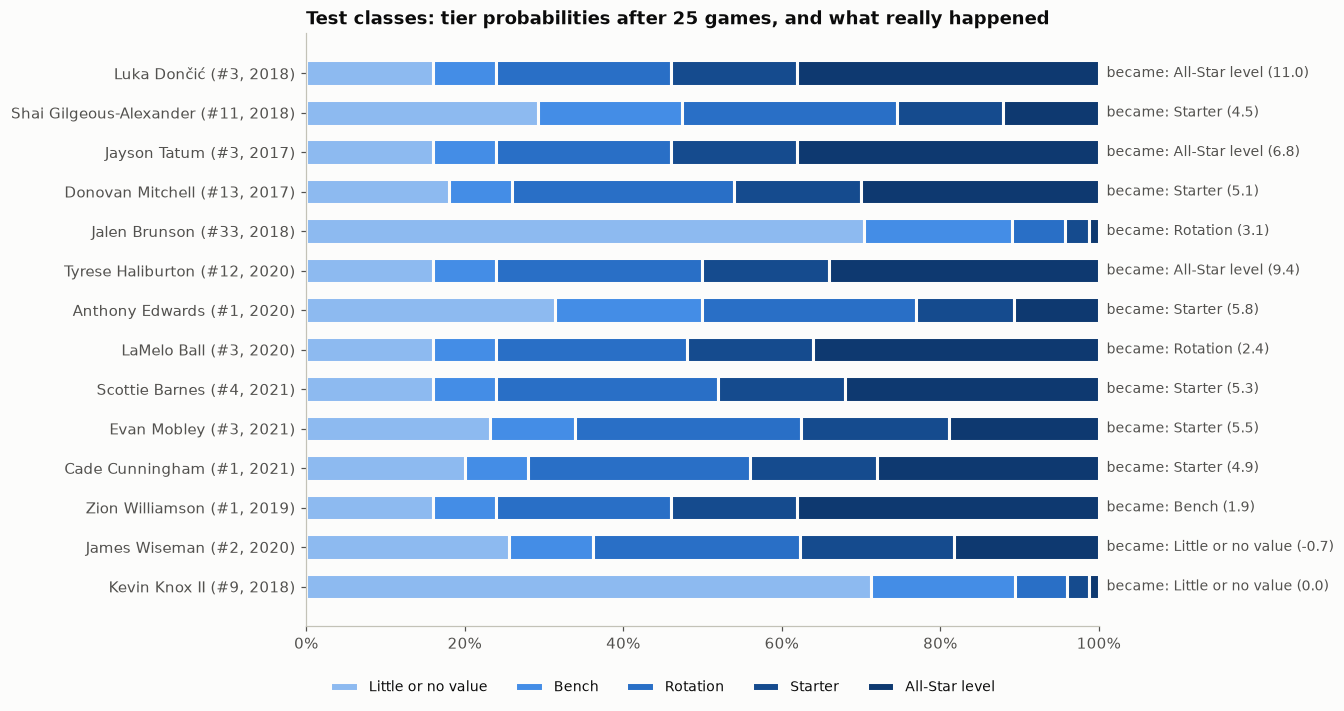

In [9]:
SHOW = ["Luka Dončić", "Shai Gilgeous-Alexander", "Jayson Tatum", "Donovan Mitchell", "Jalen Brunson",
        "Tyrese Haliburton", "Anthony Edwards", "LaMelo Ball", "Scottie Barnes", "Evan Mobley",
        "Cade Cunningham", "Zion Williamson", "James Wiseman", "Kevin Knox II"]
sel = tidx[tidx["player_name"].isin(SHOW)].copy()
sel = sel.set_index("player_name").reindex([n for n in SHOW if n in set(sel["player_name"])])
P = probs.loc[tidx.reset_index().set_index("player_name").loc[sel.index, "player_id"]]
colors = [to_hex(SEQ_BLUE(v)) for v in np.linspace(0.18, 0.95, len(pj.TIER_NAMES))]

fig, ax = plt.subplots(figsize=(11, 7))
left = np.zeros(len(sel))
for t, color in zip(pj.TIER_NAMES, colors):
    vals = P[t].to_numpy()
    ax.barh(range(len(sel)), vals, left=left, color=color, height=0.65,
            edgecolor="#fcfcfb", linewidth=2, label=t)
    left += vals
for i, (name, r) in enumerate(sel.iterrows()):
    ax.annotate(f"became: {r['tier']} ({r[m.TARGET]:.1f})", (1.01, i), va="center", fontsize=9,
                color=INK_2, annotation_clip=False)
ax.set_yticks(range(len(sel)), [f"{n} (#{int(r['pick'])}, {int(r['draft_year'])})" for n, r in sel.iterrows()])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.07), fontsize=9)
ax.set_title("Test classes: tier probabilities after 25 games, and what really happened")
plt.subplots_adjust(right=0.78)
plt.show()

## 5. Biggest corrections and biggest misses on the test classes

In [10]:
view = tidx.assign(
    baseline_err=(tidx[m.TARGET] - tidx["base_pred"]).abs(),
    model_err=(tidx[m.TARGET] - tidx["model_pred"]).abs(),
)
view["improvement"] = view["baseline_err"] - view["model_err"]
cols = ["player_name", "draft_year", "pick", "mpg", m.TARGET, "base_pred", "model_pred", "improvement"]
print(f"The model is closer than the pick alone for {100 * (view['improvement'] > 0).mean():.0f}% of test players")
print("\nWhere the first 25 games corrected the pick the most")
display(view.nlargest(10, "improvement")[cols].round(2))
print("Biggest misses")
display(view.assign(miss=view[m.TARGET] - view["model_pred"]).reindex(
    (view[m.TARGET] - view["model_pred"]).abs().sort_values(ascending=False).index[:10])[cols].round(2))

The model is closer than the pick alone for 52% of test players

Where the first 25 games corrected the pick the most


,player_name,draft_year,pick,mpg,target_vorp,base_pred,model_pred,improvement
player_id,,,,,,,,
1630169,Tyrese Haliburton,2020,12,29.22,9.4,1.31,4.99,3.68
1628369,Jayson Tatum,2017,3,30.44,6.8,3.20,6.92,3.48
1629027,Trae Young,2018,5,29.16,7.8,2.34,5.81,3.47
1628378,Donovan Mitchell,2017,13,29.16,5.1,1.30,4.74,3.44
1630578,Alperen Sengun,2021,16,17.75,7.4,1.07,4.34,3.26
1629029,Luka Dončić,2018,3,32.29,11.0,3.05,6.12,3.07
1628365,Markelle Fultz,2017,1,18.75,0.0,5.23,2.24,2.99
1630567,Scottie Barnes,2021,4,35.78,5.3,2.58,4.86,2.28
1629634,Brandon Clarke,2019,21,21.21,3.3,0.88,2.77,1.90


Biggest misses


,player_name,draft_year,pick,mpg,target_vorp,base_pred,model_pred,improvement
player_id,,,,,,,,
1628372,Dennis Smith Jr.,2017,9,28.22,-0.3,1.69,5.18,-3.49
1629029,Luka Dončić,2018,3,32.29,11.0,3.05,6.12,3.07
1628389,Bam Adebayo,2017,14,15.56,7.0,1.23,2.20,0.97
1629636,Darius Garland,2019,5,27.84,5.5,2.32,0.73,-1.59
1629628,RJ Barrett,2019,3,32.25,-0.5,3.06,4.05,-0.99
1629057,Robert Williams III,2018,27,7.42,5.4,0.71,0.86,0.14
1630169,Tyrese Haliburton,2020,12,29.22,9.4,1.31,4.99,3.68
1629627,Zion Williamson,2019,1,27.83,1.9,5.06,6.25,-1.19
1631097,Bennedict Mathurin,2022,6,28.76,-0.7,2.09,3.61,-1.52


**What to look for:** the same two stories as in development. Corrections: late
or mid picks who played a lot early, and top picks who didn't. Misses: players
who exploded after quiet starts (no 25-game model can see that) and heavy-minute
rookies who didn't hold up.

## 6. Did the minutes warning hold on the test classes?

The warning was built on the development set (07). Here it is checked, unchanged,
on the test classes: same profiles, same thresholds.

In [11]:
profile = pj.minutes_profile(tidx)
rows = {}
for name in pj.PROFILES + [""]:
    mask = profile == name
    err = (tidx[m.TARGET] - tidx["model_pred"])[mask]
    rows[name or "No profile"] = {
        "test players": int(mask.sum()), "test avg error": err.mean(),
        "dev avg error": history.loc[name, "avg_error"] if name else np.nan,
    }
check = pd.DataFrame(rows).T
display(check.round(2))
cols = ["player_name", "draft_year", "pick", "mpg", "team_net_window", m.TARGET, "model_pred"]
print("Test players with the 'heavy minutes, weak team' warning")
tidx[profile == pj.PROFILES[0]][cols].sort_values("model_pred", ascending=False).round(2)

,test players,test avg error,dev avg error
"Heavy minutes, weak team",18.0,-0.94,-0.72
"Heavy minutes, other team",15.0,-0.55,1.12
No profile,298.0,-0.30,NaN


Test players with the 'heavy minutes, weak team' warning


,player_name,draft_year,pick,mpg,team_net_window,target_vorp,model_pred
player_id,,,,,,,
1631094,Paolo Banchero,2022,1,34.33,-6.52,4.3,5.91
1629027,Trae Young,2018,5,29.16,-10.17,7.8,5.81
1629028,Deandre Ayton,2018,1,31.16,-11.18,3.8,5.46
1629630,Ja Morant,2019,2,28.95,-6.75,7.7,5.37
1631093,Jaden Ivey,2022,5,31.67,-7.90,0.8,4.47
1630595,Cade Cunningham,2021,1,32.21,-8.51,4.9,4.33
1628374,Lauri Markkanen,2017,7,30.72,-9.93,1.2,4.19
1629628,RJ Barrett,2019,3,32.25,-10.47,-0.5,4.05
1630581,Josh Giddey,2021,6,29.74,-9.17,4.5,3.33


**What to look for:** whether the test error for each profile points the same way
as in development (negative for weak teams = the model was too optimistic, positive
for other teams = too cautious).